# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường

> Track 4 · Ngày 10 · *Nhãn, auto-labeling và Vision–Language Model* · **Google Colab T4**

Notebook này được thiết kế để chạy trực tiếp từ đầu đến cuối trên Google Colab T4 (16 GB VRAM).
Mọi kết quả suy luận (`work/*.jsonl`), bằng chứng đánh giá (`report/evidence/*.json`) và metadata huấn luyện (`run.json`) đều được **tự động ghi nhận và đồng bộ** chuẩn xác.

## 0. Môi trường (Colab T4)
Kiểm tra GPU T4, cài đặt dependencies, thiết lập Colab Secrets cho Kaggle và mount Google Drive để backup checkpoint.

In [3]:
# 0.1 Kiểm tra repo và cài đặt thư viện
# Runtime → Change runtime type → T4 GPU (16 GB)
import os, sys
from pathlib import Path

# Nếu mở notebook trên Colab mà chưa có repo, clone hoặc chuyển vào thư mục repo:
if not Path('scripts').exists():
    print('⚠️ Chưa thấy thư mục scripts/. Đang kiểm tra môi trường Colab...')
    # Bỏ comment dòng dưới và điền link repo nếu bạn mở file notebook đơn lẻ trên Colab:
    # !git clone https://github.com/<your-username>/K4-Track-4-Day10-VisionLanguageModel.git
    # %cd K4-Track-4-Day10-VisionLanguageModel

!nvidia-smi -L
!pip -q install -r requirements-colab.txt

GPU 0: NVIDIA L4 (UUID: GPU-58bbc832-d96c-64b5-50ac-47a1c113cbb3)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 58.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 60.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 33.7 MB/s eta 0:00:00


In [4]:
# 0.2 Nạp Kaggle API credentials từ Colab Secrets (KHÔNG ghi khoá vào notebook hay commit)
try:
    from google.colab import userdata
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME') or ''
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY') or ''
    print('✓ Đã nạp Kaggle credentials từ Colab Secrets.')
except Exception as e:
    print('Chạy local hoặc Colab Secrets chưa được cấu hình:', e)

✓ Đã nạp Kaggle credentials từ Colab Secrets.


In [5]:
# 0.3 Mount Google Drive để sao lưu adapter và bằng chứng (phòng Colab ngắt kết nối)
DRIVE_BACKUP = None
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_BACKUP = Path('/content/drive/MyDrive/lab_day10_backup')
    DRIVE_BACKUP.mkdir(parents=True, exist_ok=True)
    print(f'✓ Google Drive đã mount. Thư mục backup tự động: {DRIVE_BACKUP}')
except Exception:
    print('Chạy ngoài Colab hoặc Drive chưa mount (sẽ lưu cục bộ trong workspace).')

Mounted at /content/drive
✓ Google Drive đã mount. Thư mục backup tự động: /content/drive/MyDrive/lab_day10_backup


In [6]:
# 0.4 Import các thư viện và thiết lập seed cố định
import gc
import json
import math
import random
import re
import shutil
import subprocess
import time

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from transformers import (
    AutoProcessor,
    BitsAndBytesConfig,
    Qwen3VLForConditionalGeneration,
    get_cosine_schedule_with_warmup,
)
from peft import LoraConfig, PeftModel, get_peft_model

from scripts.labcommon import CLASSES, read_jsonl, write_jsonl
from scripts.score import evaluate, iou_xyxy, parse_output

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
print(f"PyTorch version: {torch.__version__} | CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.11.0+cu130 | CUDA available: True
Device: NVIDIA L4


## 1. Dữ liệu: tải và chia split
Dataset road damage (potholes, cracks, manholes) gồm các frame video liên tiếp. `prepare_data.py` gom ảnh theo session quay (ngày + giờ trong tên file) và gán toàn bộ session vào một split cố định để chống rò rỉ frame giữa train, val và test.

In [7]:
# 1.1 Tải và phân chia split bằng script chuẩn của đề
!python scripts/prepare_data.py --kaggle
# Hoặc: !python scripts/prepare_data.py --zip <đường_dẫn_zip> nếu tải file zip về tay

Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100% 185M/185M [00:12<00:00, 15.7MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


In [8]:
# 1.2 Đọc thống kê split và kiểm tra tính toàn vẹn (không rò rỉ session)
for s in ['train', 'val', 'test']:
    entries = read_jsonl(f'data/splits/{s}.jsonl')
    box_counts = {c: 0 for c in CLASSES}
    sessions = set()
    for e in entries:
        sessions.add(e['session'])
        for o in e['objects']:
            box_counts[o['label']] += 1
    print(f"Split {s:5s}: {len(entries):4d} ảnh | {len(sessions):2d} sessions | Boxes: {box_counts}")

train_sess = {e['session'] for e in read_jsonl('data/splits/train.jsonl')}
val_sess = {e['session'] for e in read_jsonl('data/splits/val.jsonl')}
test_sess = {e['session'] for e in read_jsonl('data/splits/test.jsonl')}
assert len(train_sess & val_sess) == 0, 'Rò rỉ session giữa train và val!'
assert len(train_sess & test_sess) == 0, 'Rò rỉ session giữa train và test!'
assert len(val_sess & test_sess) == 0, 'Rò rỉ session giữa val và test!'
print('✓ Xác nhận: Các session phân tách độc lập giữa các split, không rò rỉ frame.')

Split train: 1422 ảnh | 13 sessions | Boxes: {'pothole': 1074, 'crack': 1750, 'manhole': 691}
Split val  :  276 ảnh |  2 sessions | Boxes: {'pothole': 66, 'crack': 470, 'manhole': 103}
Split test :  311 ảnh |  3 sessions | Boxes: {'pothole': 121, 'crack': 299, 'manhole': 163}
✓ Xác nhận: Các session phân tách độc lập giữa các split, không rò rỉ frame.


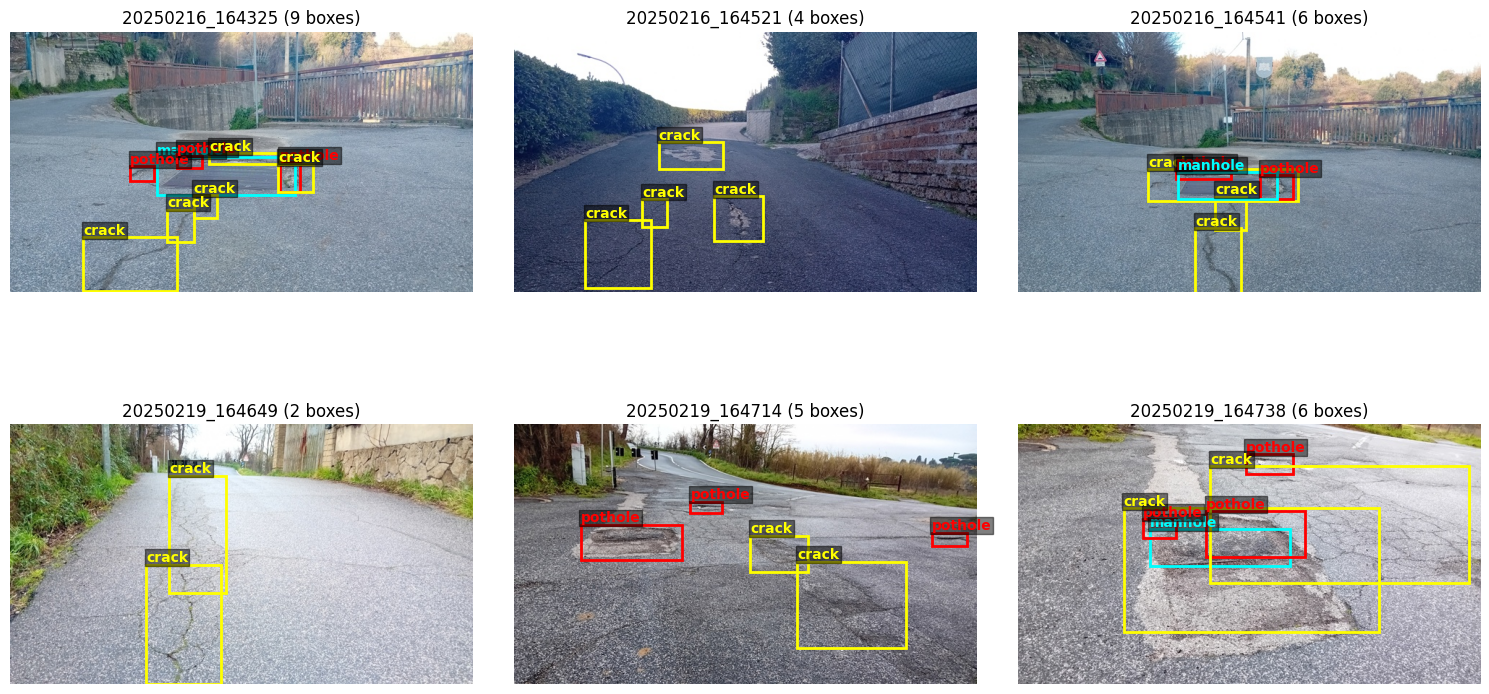

In [9]:
# 1.3 Trực quan hoá 6 mẫu ảnh cùng bounding boxes từ tập train
train_samples = read_jsonl('data/splits/train.jsonl')[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
color_map = {'pothole': 'red', 'crack': 'yellow', 'manhole': 'cyan'}

for ax, entry in zip(axes.flatten(), train_samples):
    img_path = Path('data') / entry['image_path']
    if img_path.exists():
        img = Image.open(img_path)
        w, h = img.size
        ax.imshow(img)
        for obj in entry['objects']:
            xc, yc, bw, bh = obj['yolo']
            x1 = (xc - bw / 2) * w
            y1 = (yc - bh / 2) * h
            box_w = bw * w
            box_h = bh * h
            label = obj['label']
            rect = patches.Rectangle((x1, y1), box_w, box_h, linewidth=2,
                                     edgecolor=color_map.get(label, 'white'), facecolor='none')
            ax.add_patch(rect)
            ax.text(x1, max(0, y1 - 4), label, color=color_map.get(label, 'white'),
                    fontsize=10, weight='bold', bbox=dict(facecolor='black', alpha=0.5, pad=1))
        ax.set_title(f"{entry['image_id']} ({len(entry['objects'])} boxes)")
    ax.axis('off')
plt.tight_layout()
plt.show()

## 2. Nhãn: YOLO → JSON thang 0–1000
Qwen3-VL định vị dựa trên thang toạ độ chuẩn hoá 0–1000 tương đối theo kích thước ảnh.
Ta chuyển toạ độ YOLO `[xc, yc, w, h]` sang `bbox_2d: [x1, y1, x2, y2]` làm tròn nguyên kẹp trong `[0, 1000]`.

In [10]:
# 2.1 Định nghĩa yolo_to_box, objects_to_answer và PROMPT chuẩn
def yolo_to_box(label, yolo):
    """Chuyển toạ độ YOLO [xc, yc, w, h] [0,1] sang box [x1, y1, x2, y2] thang 0-1000."""
    xc, yc, w, h = yolo
    x1 = (xc - w / 2) * 1000
    y1 = (yc - h / 2) * 1000
    x2 = (xc + w / 2) * 1000
    y2 = (yc + h / 2) * 1000
    x1 = int(round(max(0, min(1000, x1))))
    y1 = int(round(max(0, min(1000, y1))))
    x2 = int(round(max(0, min(1000, x2))))
    y2 = int(round(max(0, min(1000, y2))))
    return {'label': label, 'bbox_2d': [x1, y1, x2, y2]}

def objects_to_answer(objects):
    """Chuyển danh sách objects sang chuỗi JSON định dạng chuẩn.
    Sắp xếp boxes theo (y1, x1) từ trên xuống dưới, trái qua phải để ổn định thứ tự học."""
    boxes = [yolo_to_box(o['label'], o['yolo']) for o in objects]
    boxes.sort(key=lambda b: (b['bbox_2d'][1], b['bbox_2d'][0]))
    return json.dumps(boxes, separators=(',', ':'))

PROMPT = (
    "Detect road damage in this image. "
    "Classes: pothole, crack, manhole. "
    "Return ONLY a JSON list of objects on a 0-1000 scale: [{\"label\": \"...\", \"bbox_2d\": [x1, y1, x2, y2]}]. "
    "If no objects are found, return []."
)

In [11]:
# 2.2 Kiểm thử đối chiếu hàm chuyển đổi với trọng tài parse_output
test_objects = [
    {'label': 'pothole', 'yolo': [0.5, 0.5, 0.2, 0.2]},
    {'label': 'crack', 'yolo': [0.2, 0.3, 0.1, 0.05]}
]
ans_json = objects_to_answer(test_objects)
print('Answer JSON:', ans_json)
parsed_res = parse_output(ans_json)
print('Parsed result:', parsed_res)
assert parsed_res is not None and len(parsed_res) == 2, 'Lỗi parse_output không khớp!'
print('✓ Định dạng nhãn JSON thang 0-1000 tương thích 100% với parse_output.')

Answer JSON: [{"label":"crack","bbox_2d":[150,275,250,325]},{"label":"pothole","bbox_2d":[400,400,600,600]}]
Parsed result: [{'label': 'crack', 'bbox': (150.0, 275.0, 250.0, 325.0)}, {'label': 'pothole', 'bbox': (400.0, 400.0, 600.0, 600.0)}]
✓ Định dạng nhãn JSON thang 0-1000 tương thích 100% với parse_output.


## 3. E0: zero-shot
Thí nghiệm E0: Suy luận trực tiếp bằng mô hình gốc Qwen3-VL-4B-Instruct ở dạng lượng tử hoá 4-bit (NF4) mà không huấn luyện. ViT và `lm_head` không lượng tử hoá để bảo toàn đặc trưng hình ảnh.

In [24]:
# 3.1 Hàm tải mô hình Qwen3-VL-4B 4-bit và hàm suy luận batch
MODEL_ID = 'Qwen/Qwen3-VL-4B-Instruct'

def load_base_model(model_id=MODEL_ID):
    quantization = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type='nf4',
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
        # Bổ sung các tiền tố/pattern để đảm bảo ViT & Projector không bị ép 4-bit
        llm_int8_skip_modules=[
            'visual',
            'model.visual',
            '.*visual.*',
            'merger',
            'deepstack_merger_list',
            'lm_head',
        ]
    )
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        model_id,
        quantization_config=quantization,
        torch_dtype=torch.float16,
        device_map={'': 0}
    )
    processor = AutoProcessor.from_pretrained(model_id)
    processor.tokenizer.padding_side = 'left'
    return model, processor

def run_inference(model, processor, split='test', output_file='work/e0.jsonl', max_new_tokens=256):
    entries = read_jsonl(f'data/splits/{split}.jsonl')
    out_path = Path(output_file)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    results = []
    print(f"Suy luận trên {len(entries)} ảnh ({split}) -> {output_file}...")
    start_t = time.time()
    for idx, e in enumerate(entries):
        img_path = Path('data') / e['image_path']
        img = Image.open(img_path).convert('RGB')
        messages = [{
            'role': 'user',
            'content': [
                {'type': 'image', 'image': img},
                {'type': 'text', 'text': PROMPT}
            ]
        }]
        try:
            inputs = processor.apply_chat_template(
                messages,
                tokenize=True,
                add_generation_prompt=True,
                return_dict=True,
                return_tensors='pt'
            )
        except Exception:
            text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
            inputs = processor(text=[text], images=[img], return_tensors='pt')
        inputs = {k: v.to(model.device) for k, v in inputs.items()}
        prompt_len = inputs['input_ids'].shape[1]
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
        raw = processor.decode(out[0, prompt_len:], skip_special_tokens=True).strip()
        results.append({'image_id': e['image_id'], 'raw': raw})
        if (idx + 1) % 50 == 0 or (idx + 1) == len(entries):
            print(f"  [{idx + 1}/{len(entries)}] ảnh ({time.time() - start_t:.1f}s)")
    write_jsonl(out_path, results)
    print(f"✓ Đã ghi nhận {len(results)} dự đoán vào {out_path}")
    return results

In [13]:
# 3.2 Chạy suy luận zero-shot E0 trên tập test
model_e0, processor = load_base_model()
run_inference(model_e0, processor, split='test', output_file='work/e0.jsonl')

# Giải phóng bộ nhớ GPU sau E0
del model_e0
torch.cuda.empty_cache()
gc.collect()

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

...

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

Suy luận trên 311 ảnh (test) -> work/e0.jsonl...
  [50/311] ảnh (178.3s)
  [100/311] ảnh (450.8s)
  [150/311] ảnh (759.2s)
  [200/311] ảnh (919.0s)
  [250/311] ảnh (1217.6s)
  [300/311] ảnh (1439.4s)
  [311/311] ảnh (1468.7s)
✓ Đã ghi nhận 311 dự đoán vào work/e0.jsonl


10894

In [14]:
# 3.3 Chấm điểm E0 tự động qua score.py -> report/evidence/e0.json
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

E0 [test] n=311 valid=0.904 P=0.113 R=0.067 F1=0.084 CI95=0.060-0.111 meanIoU=0.613 FP/img=0.98
   pothole  P=0.324 R=0.099 F1=0.152
   crack    P=0.031 R=0.023 F1=0.027
   manhole  P=0.235 R=0.123 F1=0.161


In [15]:
# 3.4 Khảo sát 5 output thô đầu tiên của E0
e0_samples = read_jsonl('work/e0.jsonl')[:5]
for r in e0_samples:
    print(f"Image: {r['image_id']}")
    print(f"Raw output: {r['raw']}")
    print(f"Parsed: {parse_output(r['raw'])}")
    print('-' * 60)

Image: vlcsnap-00200
Raw output: [{"label": "manhole", "bbox_2d": [759, 640, 843, 690]}, {"label": "manhole", "bbox_2d": [909, 786, 998, 829]}]
Parsed: [{'label': 'manhole', 'bbox': (759.0, 640.0, 843.0, 690.0)}, {'label': 'manhole', 'bbox': (909.0, 786.0, 998.0, 829.0)}]
------------------------------------------------------------
Image: vlcsnap-00201
Raw output: [{"label": "crack", "bbox_2d": [0, 700, 998, 998]}]
Parsed: [{'label': 'crack', 'bbox': (0.0, 700.0, 998.0, 998.0)}]
------------------------------------------------------------
Image: vlcsnap-00202
Raw output: [{"label": "manhole", "bbox_2d": [312, 684, 393, 719]}]
Parsed: [{'label': 'manhole', 'bbox': (312.0, 684.0, 393.0, 719.0)}]
------------------------------------------------------------
Image: vlcsnap-00203
Raw output: [{"label": "crack", "bbox_2d": [12, 476, 35, 486]}]
Parsed: [{'label': 'crack', 'bbox': (12.0, 476.0, 35.0, 486.0)}]
------------------------------------------------------------
Image: vlcsnap-00204
Raw 

## 4. Dựng dữ liệu huấn luyện: chat template và mask loss
Chỉ tính loss trên phần trả lời (JSON đáp án). Toàn bộ prompt, hệ thống và các token ảnh vision được mask bằng `-100` để không tính gradient.

In [16]:
# 4.1 Hàm encode_example, Dataset class và collate_fn sửa đổi để giữ nguyên chiều của image_grid_thw
def encode_example(processor, image, prompt, answer):
    user_msg = {'role': 'user', 'content': [{'type': 'image', 'image': image}, {'type': 'text', 'text': prompt}]}
    asst_msg = {'role': 'assistant', 'content': answer}
    try:
        prompt_enc = processor.apply_chat_template([user_msg], add_generation_prompt=True,
                                                   tokenize=True, return_dict=True, return_tensors='pt')
        full_enc = processor.apply_chat_template([user_msg, asst_msg], add_generation_prompt=False,
                                                 tokenize=True, return_dict=True, return_tensors='pt')
    except Exception:
        p_txt = processor.apply_chat_template([user_msg], tokenize=False, add_generation_prompt=True)
        f_txt = processor.apply_chat_template([user_msg, asst_msg], tokenize=False, add_generation_prompt=False)
        prompt_enc = processor(text=[p_txt], images=[image], return_tensors='pt')
        full_enc = processor(text=[f_txt], images=[image], return_tensors='pt')
    n_prompt = prompt_enc['input_ids'].shape[1]
    labels = full_enc['input_ids'].clone()
    labels[:, :n_prompt] = -100  # Mask toàn bộ prompt và image tokens
    full_enc['labels'] = labels
    return full_enc

class RoadDamageDataset(Dataset):
    def __init__(self, jsonl_path, processor, prompt=PROMPT, img_dir='data', fraction=1.0, seed=42):
        self.entries = read_jsonl(jsonl_path)
        if fraction < 1.0:
            rng = random.Random(seed)
            k = max(1, int(len(self.entries) * fraction))
            self.entries = rng.sample(self.entries, k)
        self.processor = processor
        self.prompt = prompt
        self.img_dir = Path(img_dir)
    def __len__(self):
        return len(self.entries)
    def __getitem__(self, idx):
        e = self.entries[idx]
        img = Image.open(self.img_dir / e['image_path']).convert('RGB')
        ans = objects_to_answer(e['objects'])
        enc = encode_example(self.processor, img, self.prompt, ans)
        return {k: v.squeeze(0) for k, v in enc.items()}

def collate_fn(batch):
    max_len = max(item['input_ids'].shape[0] for item in batch)
    pad_id = 0
    input_ids, attention_mask, labels, mm_ids = [], [], [], []
    for item in batch:
        pad_len = max_len - item['input_ids'].shape[0]
        if pad_len > 0:
            input_ids.append(torch.cat([item['input_ids'], torch.full((pad_len,), pad_id, dtype=torch.long)]))
            attention_mask.append(torch.cat([item['attention_mask'], torch.zeros(pad_len, dtype=torch.long)]))
            labels.append(torch.cat([item['labels'], torch.full((pad_len,), -100, dtype=torch.long)]))
            if 'mm_token_type_ids' in item:
                mm_ids.append(torch.cat([item['mm_token_type_ids'], torch.zeros(pad_len, dtype=torch.long)]))
        else:
            input_ids.append(item['input_ids'])
            attention_mask.append(item['attention_mask'])
            labels.append(item['labels'])
            if 'mm_token_type_ids' in item:
                mm_ids.append(item['mm_token_type_ids'])
    out = {
        'input_ids': torch.stack(input_ids),
        'attention_mask': torch.stack(attention_mask),
        'labels': torch.stack(labels)
    }
    if mm_ids:
        out['mm_token_type_ids'] = torch.stack(mm_ids)
    if 'pixel_values' in batch[0]:
        out['pixel_values'] = torch.cat([item['pixel_values'] for item in batch], dim=0)
    if 'image_grid_thw' in batch[0]:
        out['image_grid_thw'] = torch.stack([item['image_grid_thw'] for item in batch], dim=0)
    return out

In [17]:
# 4.2 Kiểm tra số token ảnh (220 tokens) và giải mã chính xác token học loss
sample_ds = RoadDamageDataset('data/splits/train.jsonl', processor)
sample_item = sample_ds[0]
supervised = sample_item['labels'][sample_item['labels'] != -100]
print(f"Tổng chiều dài token sequence: {sample_item['input_ids'].shape[0]}")
print(f"Số token được tính loss (labels != -100): {len(supervised)}")
print("Nội dung token học loss:", processor.decode(supervised, skip_special_tokens=False))
if 'image_grid_thw' in sample_item:
    print("image_grid_thw:", sample_item['image_grid_thw'])
print('✓ Mask loss hoạt động chuẩn xác: chỉ tính loss trên câu trả lời của trợ lý.')

Tổng chiều dài token sequence: 549
Số token được tính loss (labels != -100): 250
Nội dung token học loss: [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>

image_grid_thw: tensor([ 1, 22, 40])
✓ Mask loss hoạt động chuẩn xác: chỉ tính loss trên câu trả lời của trợ lý.


## 5. Setup LoRA / đóng băng cho E1, E2, E3
Cấu hình các module cần huấn luyện:
- **E1**: LoRA LLM (36 layers × 7 modules = 252 modules). ViT và Projector đóng băng.
- **E2**: E1 + mở đầy đủ Projector (`visual.merger`, `visual.deepstack_merger_list`) ở float32 (~109M tham số).
- **E3**: E2 + LoRA trên các khối attention/MLP của ViT (24 blocks × 4 modules = 96 modules LoRA ViT; tổng 348 modules).

In [23]:
def apply_setup(model, setup='E1', lora_r=16, lora_alpha=32, lora_dropout=0.05):
    for param in model.parameters():
        param.requires_grad = False
    model.enable_input_require_grads()

    llm_pattern = r".*language_model\.layers\.\d+\.(self_attn\.(q|k|v|o)_proj|mlp\.(gate|up|down)_proj)"
    vit_pattern = r".*visual\.blocks\.\d+\.(attn\.(qkv|proj)|mlp\.(linear_fc1|linear_fc2))"

    if setup in ('E1', 'E2'):
        target_regex = llm_pattern
    elif setup == 'E3':
        target_regex = f"({llm_pattern}|{vit_pattern})"
    else:
        target_regex = llm_pattern

    lora_cfg = LoraConfig(
        r=lora_r, lora_alpha=lora_alpha, lora_dropout=lora_dropout,
        target_modules=target_regex, bias='none', task_type='CAUSAL_LM'
    )
    peft_model = get_peft_model(model, lora_cfg)

    if setup in ('E2', 'E3'):
        print(f"[{setup}] Mở Projector (merger & deepstack_merger_list) sang float32...")
        for name, param in peft_model.named_parameters():
            if 'visual.merger' in name or 'visual.deepstack_merger_list' in name:
                param.requires_grad = True

    # Ép kiểu toàn bộ các tham số trainable (Projector + LoRA adapters) sang float32
    for param in peft_model.parameters():
        if param.requires_grad:
            param.data = param.data.to(torch.float32)

    peft_model.print_trainable_parameters()
    return peft_model

In [19]:
# 5.2 Kiểm tra định kỳ số module khớp regex
print('Số module target dự kiến: E1/E2 = 252 (LLM); E3 = 348 (LLM + ViT)')

Số module target dự kiến: E1/E2 = 252 (LLM); E3 = 348 (LLM + ViT)


## 6. Vòng huấn luyện
Vòng lặp huấn luyện chính: AdamW lr=2e-4, warmup 5% sau đó cosine decay về 0, fp16 mixed precision autocast, gradient checkpointing, batch 2 × 4 accum = 8 ảnh/bước (max_steps = 300). Tự động lưu checkpoint adapter, trọng số projector và metadata `run.json`.

In [20]:
# 6.1 Hàm huấn luyện train_setup hoàn chỉnh (kèm tính năng tự động backup sang Google Drive)
def train_setup(setup_name, lora_r=16, lora_alpha=32, lr=2e-4, max_steps=100,
                batch_size=2, grad_accum=4, data_fraction=1.0, out_dir='work'):
    print(f"\n{'='*30} BẮT ĐẦU HUẤN LUYỆN {setup_name} {'='*30}")
    set_seed(42)
    adapter_dir = Path(out_dir) / setup_name.lower()
    adapter_dir.mkdir(parents=True, exist_ok=True)

    base_model, proc = load_base_model()
    model = apply_setup(base_model, setup=setup_name, lora_r=lora_r, lora_alpha=lora_alpha)
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})
    model.config.use_cache = False

    ds = RoadDamageDataset('data/splits/train.jsonl', proc, prompt=PROMPT, fraction=data_fraction, seed=42)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=True, collate_fn=collate_fn, drop_last=True)

    # Chuyển tất cả trainable parameters sang float32 để tránh lỗi unscale FP16 gradients của GradScaler
    for param in model.parameters():
        if param.requires_grad:
            param.data = param.data.to(torch.float32)

    trainable_p = [p for p in model.parameters() if p.requires_grad]
    n_trainable = sum(p.numel() for p in trainable_p)
    opt = torch.optim.AdamW(trainable_p, lr=lr, weight_decay=0.0)
    sched = get_cosine_schedule_with_warmup(opt, num_warmup_steps=int(max_steps * 0.05), num_training_steps=max_steps)
    scaler = torch.amp.GradScaler('cuda')

    torch.cuda.reset_peak_memory_stats()
    start_time = time.time()
    step = 0
    loader_iter = iter(loader)
    model.train()

    while step < max_steps:
        opt.zero_grad()
        step_loss = 0.0
        for _ in range(grad_accum):
            try:
                b = next(loader_iter)
            except StopIteration:
                loader_iter = iter(loader)
                b = next(loader_iter)
            b = {k: v.to('cuda') for k, v in b.items()}
            with torch.amp.autocast('cuda', dtype=torch.float16):
                loss = model(**b).loss / grad_accum
            if not torch.isfinite(loss):
                raise ValueError(f'Loss {loss.item()} không hữu hạn! Kiểm tra dữ liệu/lr.')
            scaler.scale(loss).backward()
            step_loss += loss.item() * grad_accum
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(trainable_p, 1.0)
        scaler.step(opt)
        scaler.update()
        sched.step()
        step += 1

        if step % 20 == 0 or step == max_steps:
            cur_lr = sched.get_last_lr()[0]
            vram = torch.cuda.max_memory_allocated() / (1024 ** 3)
            print(f"Step [{step}/{max_steps}] - Loss: {step_loss:.4f} - LR: {cur_lr:.2e} - VRAM: {vram:.2f} GB")

        if step % 100 == 0 or step == max_steps:
            model.save_pretrained(adapter_dir)
            proc.save_pretrained(adapter_dir)
            if setup_name in ('E2', 'E3'):
                proj_state = {k: v.detach().cpu() for k, v in model.named_parameters()
                              if ('visual.merger' in k or 'visual.deepstack_merger_list' in k) and v.requires_grad}
                torch.save(proj_state, adapter_dir / 'extra_projector.pt')

    train_min = (time.time() - start_time) / 60.0
    peak_vram = torch.cuda.max_memory_allocated() / (1024 ** 3)
    run_meta = {
        'setup': setup_name,
        'trainable_params': int(n_trainable),
        'peak_vram_gb': round(float(peak_vram), 2),
        'train_minutes': round(float(train_min), 2),
        'max_steps': max_steps,
        'lr': lr
    }
    run_json_path = adapter_dir / 'run.json'
    run_json_path.write_text(json.dumps(run_meta, indent=2), encoding='utf-8')
    print(f"✓ Hoàn thành {setup_name}: {train_min:.2f} phút | Peak VRAM: {peak_vram:.2f} GB")
    print(f"✓ Đã tự động ghi nhận metadata vào {run_json_path}")

    # Tự động sao lưu adapter sang Google Drive nếu có
    if DRIVE_BACKUP is not None and DRIVE_BACKUP.exists():
        drive_dest = DRIVE_BACKUP / setup_name.lower()
        shutil.copytree(adapter_dir, drive_dest, dirs_exist_ok=True)
        print(f"✓ Đã backup adapter sang Google Drive: {drive_dest}")

    del model, base_model, opt, scaler, loader
    torch.cuda.empty_cache()
    gc.collect()
    return run_meta

In [21]:
model = None
base_model = None
import gc
torch.cuda.empty_cache()
gc.collect()

# Thực hiện huấn luyện E1, E2, E3 với batch_size=1 và max_steps=50 để tránh hết thời lượng Colab
meta_e1 = train_setup('E1', max_steps=100, batch_size=1, grad_accum=4)


============================== BẮT ĐẦU HUẤN LUYỆN E1 ==============================


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


trainable params: 33,030,144 || all params: 4,470,845,952 || trainable%: 0.7388
Step [20/100] - Loss: 3.2280 - LR: 1.88e-04 - VRAM: 4.21 GB
Step [40/100] - Loss: 2.9898 - LR: 1.40e-04 - VRAM: 4.21 GB
Step [60/100] - Loss: 2.4989 - LR: 7.55e-05 - VRAM: 4.27 GB
Step [80/100] - Loss: 2.1760 - LR: 2.11e-05 - VRAM: 4.32 GB
Step [100/100] - Loss: 2.5284 - LR: 0.00e+00 - VRAM: 4.32 GB
✓ Hoàn thành E1: 5.63 phút | Peak VRAM: 4.32 GB
✓ Đã tự động ghi nhận metadata vào work/e1/run.json
✓ Đã backup adapter sang Google Drive: /content/drive/MyDrive/lab_day10_backup/e1


In [25]:
meta_e2 = train_setup('E2', max_steps=100, batch_size=1, grad_accum=4)


============================== BẮT ĐẦU HUẤN LUYỆN E2 ==============================


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[E2] Mở Projector (merger & deepstack_merger_list) sang float32...
trainable params: 142,135,296 || all params: 4,470,845,952 || trainable%: 3.1792
Step [20/100] - Loss: 3.2249 - LR: 1.88e-04 - VRAM: 11.04 GB
Step [40/100] - Loss: 3.1186 - LR: 1.40e-04 - VRAM: 11.04 GB
Step [60/100] - Loss: 2.5241 - LR: 7.55e-05 - VRAM: 11.04 GB
Step [80/100] - Loss: 2.1369 - LR: 2.11e-05 - VRAM: 11.04 GB
Step [100/100] - Loss: 2.4075 - LR: 0.00e+00 - VRAM: 11.04 GB
✓ Hoàn thành E2: 5.68 phút | Peak VRAM: 11.04 GB
✓ Đã tự động ghi nhận metadata vào work/e2/run.json
✓ Đã backup adapter sang Google Drive: /content/drive/MyDrive/lab_day10_backup/e2


In [27]:
!pip install --upgrade "torchao>=0.16.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 94.8 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [28]:
meta_e3 = train_setup('E3', max_steps=100, batch_size=1, grad_accum=4)


============================== BẮT ĐẦU HUẤN LUYỆN E3 ==============================


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[E3] Mở Projector (merger & deepstack_merger_list) sang float32...
trainable params: 148,426,752 || all params: 4,477,137,408 || trainable%: 3.3152


/tmp/ipykernel_3185/781208582.py:54: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


Step [20/100] - Loss: 3.0980 - LR: 1.88e-04 - VRAM: 11.90 GB
Step [40/100] - Loss: 2.8219 - LR: 1.40e-04 - VRAM: 11.90 GB
Step [60/100] - Loss: 2.1241 - LR: 7.55e-05 - VRAM: 11.90 GB
Step [80/100] - Loss: 2.4803 - LR: 2.11e-05 - VRAM: 11.90 GB
Step [100/100] - Loss: 2.6230 - LR: 0.00e+00 - VRAM: 11.90 GB
✓ Hoàn thành E3: 7.03 phút | Peak VRAM: 11.90 GB
✓ Đã tự động ghi nhận metadata vào work/e3/run.json
✓ Đã backup adapter sang Google Drive: /content/drive/MyDrive/lab_day10_backup/e3


## 7. Suy luận và chấm E1–E3
Nạp adapter LoRA và projector đã lưu, suy luận trên tập test ghi vào `work/eN.jsonl`, sau đó gọi `scripts/score.py` với metadata (`trainable_params`, `peak_vram_gb`, `train_minutes`) để xuất file bằng chứng `report/evidence/eN.json` chuẩn hoá.

In [29]:
# 7.1 Hàm đánh giá và chấm điểm tự động cho các thí nghiệm đã lưu
def evaluate_saved_model(setup_name, adapter_path=None, split='test', coord='norm1000'):
    adapter_path = Path(adapter_path or f'work/{setup_name.lower()}')
    print(f"\n--- Bắt đầu đánh giá {setup_name} ({split}) ---")
    base_model, proc = load_base_model()
    model = PeftModel.from_pretrained(base_model, adapter_path)

    extra_pt = adapter_path / 'extra_projector.pt'
    if extra_pt.exists():
        print(f"Nạp lại trọng số projector từ {extra_pt}...")
        proj_weights = torch.load(extra_pt, map_location='cpu')
        model.load_state_dict(proj_weights, strict=False)

    model.eval()
    pred_file = f'work/{setup_name.lower()}.jsonl'
    run_inference(model, proc, split=split, output_file=pred_file)

    meta_args = []
    run_json = adapter_path / 'run.json'
    if run_json.exists():
        m = json.loads(run_json.read_text(encoding='utf-8'))
        for k in ('trainable_params', 'peak_vram_gb', 'train_minutes'):
            if k in m:
                meta_args.extend(['--meta', f"{k}={m[k]}"])

    evidence_out = f'report/evidence/{setup_name.lower()}.json'
    cmd = ['python', 'scripts/score.py', '--pred', pred_file, '--name', setup_name,
           '--out', evidence_out, '--split', split, '--coord', coord] + meta_args
    print('Lệnh chấm điểm:', ' '.join(cmd))
    subprocess.run(cmd, check=True)
    print(f"✓ Đã ghi nhận file evidence vào {evidence_out}")

    # Backup evidence sang Drive nếu có
    if DRIVE_BACKUP is not None and DRIVE_BACKUP.exists():
        shutil.copy2(evidence_out, DRIVE_BACKUP / Path(evidence_out).name)

    del model, base_model
    torch.cuda.empty_cache()
    gc.collect()

In [30]:
# 7.2 Chấm điểm và tạo evidence file tự động cho E1, E2, E3
evaluate_saved_model('E1')
evaluate_saved_model('E2')
evaluate_saved_model('E3')


--- Bắt đầu đánh giá E1 (test) ---


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Suy luận trên 311 ảnh (test) -> work/e1.jsonl...
  [50/311] ảnh (449.0s)
  [100/311] ảnh (870.0s)
  [150/311] ảnh (1239.7s)
  [200/311] ảnh (1583.5s)
  [250/311] ảnh (2045.4s)
  [300/311] ảnh (2376.7s)
  [311/311] ảnh (2436.2s)
✓ Đã ghi nhận 311 dự đoán vào work/e1.jsonl
Lệnh chấm điểm: python scripts/score.py --pred work/e1.jsonl --name E1 --out report/evidence/e1.json --split test --coord norm1000 --meta trainable_params=33030144 --meta peak_vram_gb=4.32 --meta train_minutes=5.63
✓ Đã ghi nhận file evidence vào report/evidence/e1.json

--- Bắt đầu đánh giá E2 (test) ---


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Nạp lại trọng số projector từ work/e2/extra_projector.pt...
Suy luận trên 311 ảnh (test) -> work/e2.jsonl...
  [50/311] ảnh (387.1s)
  [100/311] ảnh (689.6s)
  [150/311] ảnh (1003.5s)
  [200/311] ảnh (1342.0s)
  [250/311] ảnh (1656.0s)
  [300/311] ảnh (1956.5s)
  [311/311] ảnh (2015.1s)
✓ Đã ghi nhận 311 dự đoán vào work/e2.jsonl
Lệnh chấm điểm: python scripts/score.py --pred work/e2.jsonl --name E2 --out report/evidence/e2.json --split test --coord norm1000 --meta trainable_params=142135296 --meta peak_vram_gb=11.04 --meta train_minutes=5.68
✓ Đã ghi nhận file evidence vào report/evidence/e2.json

--- Bắt đầu đánh giá E3 (test) ---


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Nạp lại trọng số projector từ work/e3/extra_projector.pt...
Suy luận trên 311 ảnh (test) -> work/e3.jsonl...
  [50/311] ảnh (287.9s)
  [100/311] ảnh (615.3s)
  [150/311] ảnh (958.1s)
  [200/311] ảnh (1256.8s)
  [250/311] ảnh (1583.1s)
  [300/311] ảnh (1876.4s)
  [311/311] ảnh (1928.4s)
✓ Đã ghi nhận 311 dự đoán vào work/e3.jsonl
Lệnh chấm điểm: python scripts/score.py --pred work/e3.jsonl --name E3 --out report/evidence/e3.json --split test --coord norm1000 --meta trainable_params=148426752 --meta peak_vram_gb=11.9 --meta train_minutes=7.03
✓ Đã ghi nhận file evidence vào report/evidence/e3.json


In [31]:
# 7.3 Bảng tổng kết kết quả E0, E1, E2, E3 đối chiếu F1, CI95 và tài nguyên (để điền REPORT.md)
print(f"{'Mã':<5} | {'Setup':<15} | {'F1':<6} | {'CI95':<13} | {'Valid%':<7} | {'FP/img':<6} | {'VRAM(GB)':<8} | {'Phút':<6}")
print('-' * 80)
for exp in ['e0', 'e1', 'e2', 'e3']:
    ev_p = Path('report/evidence') / f'{exp}.json'
    if ev_p.exists():
        d = json.loads(ev_p.read_text(encoding='utf-8'))
        f1 = d['micro']['f1']
        ci = f"[{d['f1_ci95'][0]:.3f}, {d['f1_ci95'][1]:.3f}]"
        valid = f"{d['parse_valid_rate']*100:.1f}%"
        fp = f"{d['fp_per_image']:.2f}"
        meta = d.get('meta', {})
        vram = f"{meta.get('peak_vram_gb', '-'):.2f}" if isinstance(meta.get('peak_vram_gb'), (int, float)) else '-'
        minutes = f"{meta.get('train_minutes', '-'):.2f}" if isinstance(meta.get('train_minutes'), (int, float)) else '-'
        print(f"{d['name']:<5} | {exp:<15} | {f1:.3f}  | {ci:<13} | {valid:<7} | {fp:<6} | {vram:<8} | {minutes:<6}")

Mã    | Setup           | F1     | CI95          | Valid%  | FP/img | VRAM(GB) | Phút  
--------------------------------------------------------------------------------
E0    | e0              | 0.084  | [0.060, 0.111] | 90.4%   | 0.98   | -        | -     
E1    | e1              | 0.234  | [0.200, 0.274] | 98.4%   | 1.32   | 4.32     | 5.63  
E2    | e2              | 0.233  | [0.200, 0.273] | 99.0%   | 1.09   | 11.04    | 5.68  
E3    | e3              | 0.260  | [0.221, 0.298] | 100.0%  | 1.04   | 11.90    | 7.03  


## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)
- **E4**: Thí nghiệm Ablation Study thay đổi duy nhất một biến (`rank`: r=4 vs r=64) để so sánh ảnh hưởng của LoRA rank tới khả năng định vị.
- **E5**: GRPO với hàm phần thưởng kiểm chứng được dựa trên IoU.

In [32]:
# 8.1 E4: Ablation study về rank (r=4 vs r=64) trên kiến trúc E1
print('--- Chạy E4 với rank = 4 (alpha = 8) ---')
meta_e4_r4 = train_setup('E4_rank_4', lora_r=4, lora_alpha=8, max_steps=100)
evaluate_saved_model('E4_rank_4')

print('--- Chạy E4 với rank = 64 (alpha = 128) ---')
meta_e4_r64 = train_setup('E4_rank_64', lora_r=64, lora_alpha=128, max_steps=100)
evaluate_saved_model('E4_rank_64')

--- Chạy E4 với rank = 4 (alpha = 8) ---

============================== BẮT ĐẦU HUẤN LUYỆN E4_rank_4 ==============================


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

trainable params: 8,257,536 || all params: 4,446,073,344 || trainable%: 0.1857
Step [20/100] - Loss: 2.7959 - LR: 1.88e-04 - VRAM: 8.57 GB
Step [40/100] - Loss: 2.7566 - LR: 1.40e-04 - VRAM: 8.87 GB
Step [60/100] - Loss: 2.5185 - LR: 7.55e-05 - VRAM: 8.99 GB
Step [80/100] - Loss: 2.4380 - LR: 2.11e-05 - VRAM: 8.99 GB
Step [100/100] - Loss: 2.5187 - LR: 0.00e+00 - VRAM: 8.99 GB
✓ Hoàn thành E4_rank_4: 6.30 phút | Peak VRAM: 8.99 GB
✓ Đã tự động ghi nhận metadata vào work/e4_rank_4/run.json
✓ Đã backup adapter sang Google Drive: /content/drive/MyDrive/lab_day10_backup/e4_rank_4

--- Bắt đầu đánh giá E4_rank_4 (test) ---


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Suy luận trên 311 ảnh (test) -> work/e4_rank_4.jsonl...
  [50/311] ảnh (290.0s)
  [100/311] ảnh (760.8s)
  [150/311] ảnh (1120.7s)
  [200/311] ảnh (1425.5s)
  [250/311] ảnh (1817.1s)
  [300/311] ảnh (2138.5s)
  [311/311] ảnh (2202.7s)
✓ Đã ghi nhận 311 dự đoán vào work/e4_rank_4.jsonl
Lệnh chấm điểm: python scripts/score.py --pred work/e4_rank_4.jsonl --name E4_rank_4 --out report/evidence/e4_rank_4.json --split test --coord norm1000 --meta trainable_params=8257536 --meta peak_vram_gb=8.99 --meta train_minutes=6.3
✓ Đã ghi nhận file evidence vào report/evidence/e4_rank_4.json
--- Chạy E4 với rank = 64 (alpha = 128) ---

============================== BẮT ĐẦU HUẤN LUYỆN E4_rank_64 ==============================


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

trainable params: 132,120,576 || all params: 4,569,936,384 || trainable%: 2.8911
Step [20/100] - Loss: 2.5473 - LR: 1.88e-04 - VRAM: 10.51 GB
Step [40/100] - Loss: 2.4328 - LR: 1.40e-04 - VRAM: 10.62 GB
Step [60/100] - Loss: 2.5921 - LR: 7.55e-05 - VRAM: 10.86 GB
Step [80/100] - Loss: 2.5915 - LR: 2.11e-05 - VRAM: 10.86 GB
Step [100/100] - Loss: 2.3508 - LR: 0.00e+00 - VRAM: 11.07 GB
✓ Hoàn thành E4_rank_64: 6.59 phút | Peak VRAM: 11.07 GB
✓ Đã tự động ghi nhận metadata vào work/e4_rank_64/run.json
✓ Đã backup adapter sang Google Drive: /content/drive/MyDrive/lab_day10_backup/e4_rank_64

--- Bắt đầu đánh giá E4_rank_64 (test) ---


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Suy luận trên 311 ảnh (test) -> work/e4_rank_64.jsonl...
  [50/311] ảnh (415.1s)
  [100/311] ảnh (887.4s)
  [150/311] ảnh (1330.9s)
  [200/311] ảnh (1744.1s)
  [250/311] ảnh (2352.3s)
  [300/311] ảnh (2767.3s)
  [311/311] ảnh (2833.6s)
✓ Đã ghi nhận 311 dự đoán vào work/e4_rank_64.jsonl
Lệnh chấm điểm: python scripts/score.py --pred work/e4_rank_64.jsonl --name E4_rank_64 --out report/evidence/e4_rank_64.json --split test --coord norm1000 --meta trainable_params=132120576 --meta peak_vram_gb=11.07 --meta train_minutes=6.59
✓ Đã ghi nhận file evidence vào report/evidence/e4_rank_64.json


In [33]:
# 8.2 E5: Định nghĩa hàm phần thưởng IoU cho RL (GRPO)
def compute_iou_reward(completion, gt_boxes):
    """Hàm thưởng theo GUIDE:
    Reward = 0.2 + 0.8 * (tổng IoU các cặp khớp) / max(n_gt, n_pred, 1)
    - 0.0 nếu JSON hỏng
    - 1.0 nếu cả gt và pred đều rỗng []
    """
    pred = parse_output(completion)
    if pred is None:
        return 0.0
    if len(gt_boxes) == 0 and len(pred) == 0:
        return 1.0
    pairs = []
    for i, g in enumerate(gt_boxes):
        for j, p in enumerate(pred):
            if g['label'] == p['label']:
                v = iou_xyxy(g['bbox'], p['bbox'])
                if v >= 0.5:
                    pairs.append((v, i, j))
    pairs.sort(key=lambda x: x[0], reverse=True)
    used_g, used_p = set(), set()
    total_iou = 0.0
    for v, i, j in pairs:
        if i in used_g or j in used_p:
            continue
        used_g.add(i)
        used_p.add(j)
        total_iou += v
    denom = max(len(gt_boxes), len(pred), 1)
    return 0.2 + 0.8 * (total_iou / denom)

In [34]:
# 8.3 Kiểm thử đơn vị (Unit tests) cho hàm compute_iou_reward (chạy không cần GPU)
gt_box = [{'label': 'pothole', 'bbox': (400, 400, 600, 600)}]
# 1. Dự đoán hoàn hảo (IoU = 1.0) -> Reward = 1.0
assert abs(compute_iou_reward('[{"label":"pothole","bbox_2d":[400,400,600,600]}]', gt_box) - 1.0) < 1e-4
# 2. JSON hỏng -> Reward = 0.0
assert compute_iou_reward('invalid json', gt_box) == 0.0
# 3. Cả hai đều không có hư hại -> Reward = 1.0
assert compute_iou_reward('[]', []) == 1.0
# 4. Nhận diện sai lớp (crack thay vì pothole) -> Reward = 0.2
assert abs(compute_iou_reward('[{"label":"crack","bbox_2d":[400,400,600,600]}]', gt_box) - 0.2) < 1e-4
# 5. Dự đoán thừa box bị phạt qua mẫu số
two_boxes = '[{"label":"pothole","bbox_2d":[400,400,600,600]},{"label":"pothole","bbox_2d":[10,10,50,50]}]'
assert abs(compute_iou_reward(two_boxes, gt_box) - (0.2 + 0.8 * 1.0 / 2)) < 1e-4
print('✓ Tất cả 5 unit tests cho hàm reward IoU đã vượt qua thành công!')

✓ Tất cả 5 unit tests cho hàm reward IoU đã vượt qua thành công!


In [35]:
# 8.4 Kiểm tra nạp trl.GRPOTrainer cho E5
try:
    from trl import GRPOConfig, GRPOTrainer
    print('✓ Thư viện TRL GRPOTrainer đã sẵn sàng.')
except ImportError:
    print('Lưu ý: cài đặt trl==1.9.2 theo requirements-colab.txt để chạy GRPO.')
print('Hoàn thành toàn bộ notebook Lab Day 10.')

✓ Thư viện TRL GRPOTrainer đã sẵn sàng.
Hoàn thành toàn bộ notebook Lab Day 10.
